# Notebook 04 — Optimización de portafolio: VQE y QAOA frente al óptimo exacto

## Diseño del experimento

Se eligen exactamente $B=3$ de 6 acciones minimizando
$$\min_{x\in\{0,1\}^n}\; q\,x^\top\Sigma x-\mu^\top x\quad\text{s.t.}\quad \sum_i x_i=B,\qquad q=0.5,$$
donde $\mu$ y $\Sigma$ son la media y la covarianza **anualizadas** (252 sesiones) de los log-retornos diarios.

| | Exacto | VQE | QAOA |
|---|---|---|---|
| **Método** | Enumeración de las $\binom{6}{3}=20$ carteras factibles | `TwoLocal` ($R_Y$+CZ, 3 capas) + COBYLA | `QAOAAnsatz` ($p=3$) + COBYLA |
| **Garantía** | Óptimo global | Heurístico (variacional) | Heurístico (variacional) |
| **Restricción** | Directa | Penalización cuadrática en el QUBO | Penalización cuadrática en el QUBO |

## Datos

Precios de cierre ajustados de **Yahoo Finance** (`yfinance`) de seis acciones: EC (Ecopetrol, ADR), CIB (Bancolombia, ADR),
AAPL, MSFT, GOOGL y AMZN, del 2022-01-03 al 2023-12-29 (501 sesiones). La descarga se guarda en
`data/output/input/portfolio_prices.csv` para que el cuaderno sea reproducible; con `REFRESCAR_YAHOO=1` se vuelve a descargar.
Yahoo reajusta los cierres históricos cuando paga dividendos, así que una descarga posterior difiere de la anterior por un factor
constante en cada activo, y **los log-retornos (y por tanto $\mu$, $\Sigma$ y el problema) no cambian**.

Las estadísticas de varias semillas (Sección 7) las genera `python -m qml_v2.portfolio` y este cuaderno las lee.

## 1. Configuración

In [1]:
import os, sys, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.optimize import minimize

warnings.filterwarnings("ignore")
sys.path.insert(0, str(Path("..").resolve()))

import qiskit
from qiskit.circuit.library import TwoLocal, QAOAAnsatz
from qiskit.primitives import StatevectorEstimator, StatevectorSampler
from qiskit_finance.applications.optimization import PortfolioOptimization
from qiskit_optimization.converters import QuadraticProgramToQubo

from qml_v2 import portfolio as pf

plt.style.use("seaborn-v0_8-darkgrid")
plt.rcParams.update({"figure.figsize": (12, 6), "font.size": 11})

OUT_METRICS = Path("../data/output/metrics")
OUT_FIGURES = Path("../data/output/figures")
OUT_FIGURES.mkdir(parents=True, exist_ok=True)

TICKERS = pf.TICKERS
NUM_ASSETS, BUDGET, Q_RISK = len(TICKERS), pf.BUDGET, pf.RISK
QAOA_REPS = pf.QAOA_REPS
SEED = 0
print(f"Qiskit {qiskit.__version__} | activos={NUM_ASSETS} | presupuesto={BUDGET} | q={Q_RISK}")

Qiskit 2.6.1 | activos=6 | presupuesto=3 | q=0.5


## 2. Carga de datos — Yahoo Finance

In [2]:
START_DATE, END_DATE = "2022-01-01", "2024-01-01"
CACHE_PATH = pf.PRICES

if os.environ.get("REFRESCAR_YAHOO") == "1":
    import yfinance as yf
    raw = yf.download(TICKERS, start=START_DATE, end=END_DATE, auto_adjust=True, progress=False)
    prices_df = raw["Close"].dropna()[TICKERS]
    prices_df.to_csv(CACHE_PATH)
    print(f"Descargado de Yahoo Finance y guardado en {CACHE_PATH}")
else:
    prices_df = pd.read_csv(CACHE_PATH, index_col=0, parse_dates=True)[TICKERS]
    print(f"Leído de {CACHE_PATH}")

assert prices_df.notna().all().all() and len(prices_df) == 501
print(f"Periodo : {prices_df.index[0].date()} a {prices_df.index[-1].date()}")
print(f"Sesiones: {len(prices_df)} | activos: {list(prices_df.columns)}")
prices_df.tail(3)

Leído de /workspace/POCs/data/output/input/portfolio_prices.csv
Periodo : 2022-01-03 a 2023-12-29
Sesiones: 501 | activos: ['EC', 'CIB', 'AAPL', 'MSFT', 'GOOGL', 'AMZN']


,EC,CIB,AAPL,MSFT,GOOGL,AMZN
Date,,,,,,
2023-12-27,9.154860,20.625591,190.823563,366.251099,139.046860,153.339996
2023-12-28,9.041556,20.612183,191.248367,367.435760,138.908173,153.380005
2023-12-29,9.003790,20.625591,190.211014,368.179932,138.373291,151.940002


## 3. Retornos, $\mu$ y $\Sigma$

       mu anual  volatilidad anual
EC       0.1249             0.4228
CIB      0.0982             0.3646
AAPL     0.0340             0.2904
MSFT     0.0678             0.3069
GOOGL   -0.0188             0.3492
AMZN    -0.0578             0.4258


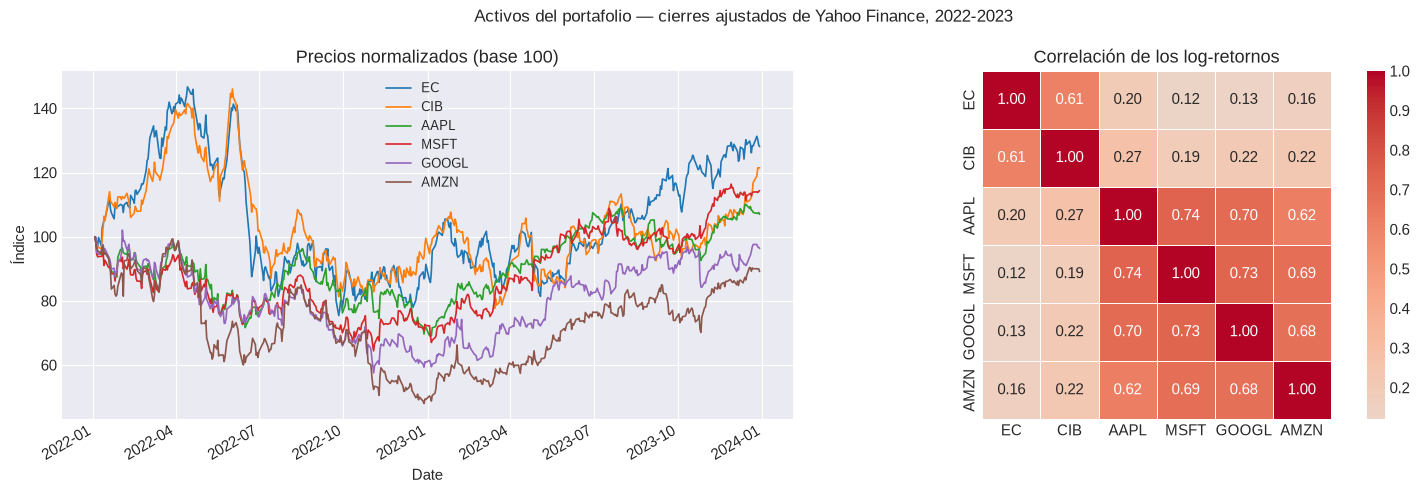

In [3]:
returns_df = np.log(prices_df / prices_df.shift(1)).dropna()
mu = returns_df.mean().values * pf.TRADING_DAYS
sigma = returns_df.cov().values * pf.TRADING_DAYS

resumen_activos = pd.DataFrame({"mu anual": mu, "volatilidad anual": np.sqrt(np.diag(sigma))}, index=TICKERS)
print(resumen_activos.round(4).to_string())

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
fig.suptitle("Activos del portafolio — cierres ajustados de Yahoo Finance, 2022-2023", fontsize=12)
(prices_df / prices_df.iloc[0] * 100).plot(ax=axes[0], linewidth=1.2)
axes[0].set_title("Precios normalizados (base 100)"); axes[0].set_ylabel("Índice"); axes[0].legend(fontsize=9)
sns.heatmap(returns_df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[1], square=True, linewidths=0.5)
axes[1].set_title("Correlación de los log-retornos")
plt.tight_layout()
plt.savefig(OUT_FIGURES / "04_portafolio_eda.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Problema cuadrático y óptimo exacto

`PortfolioOptimization` construye el problema; el óptimo exacto es la mejor de las 20 carteras de 3 activos.
Se comprueba además que el **estado fundamental** del Hamiltoniano de Ising con penalización $P=10$ (diagonalización exacta)
codifica esa misma cartera, lo que valida la formulación QUBO antes de usar solvers variacionales.

In [4]:
portfolio = PortfolioOptimization(expected_returns=mu, covariances=sigma, risk_factor=Q_RISK, budget=BUDGET)
qp = portfolio.to_quadratic_program()

t0 = time.time()
exact_cost, exact_x = pf.fuerza_bruta(qp)
t_exact = time.time() - t0
exact_assets = [TICKERS[i] for i in np.flatnonzero(exact_x)]
print(f"Óptimo exacto: {exact_assets} | coste = {exact_cost:.4f} | {t_exact*1000:.2f} ms")

todas = []
import itertools
for comb in itertools.combinations(range(NUM_ASSETS), BUDGET):
    x = np.zeros(NUM_ASSETS, dtype=int); x[list(comb)] = 1
    todas.append({"activos": ", ".join(TICKERS[i] for i in comb), "coste": qp.objective.evaluate(x),
                  "retorno": float(mu @ x), "riesgo": float(np.sqrt(x @ sigma @ x))})
tabla_carteras = pd.DataFrame(todas).sort_values("coste").reset_index(drop=True)
print("\nLas 5 mejores de las 20 carteras factibles:")
print(tabla_carteras.head(5).round(4).to_string())

bits_gs, energia_gs = pf.estado_fundamental(qp, 10.0)
gs_assets = [TICKERS[i] for i in np.flatnonzero(pf._bits(bits_gs))]
print(f"\nEstado fundamental (P=10): {gs_assets}, energía = {energia_gs:.4f}")
assert gs_assets == exact_assets and abs(energia_gs - exact_cost) < 1e-6

Óptimo exacto: ['EC', 'CIB', 'MSFT'] | coste = 0.0437 | 5.08 ms

Las 5 mejores de las 20 carteras factibles:
           activos   coste  retorno  riesgo
0    EC, CIB, MSFT  0.0437   0.2908  0.8180
1   EC, AAPL, MSFT  0.0586   0.2267  0.7554
2  CIB, AAPL, MSFT  0.0716   0.2000  0.7370
3    EC, CIB, AAPL  0.0891   0.2571  0.8321
4  EC, MSFT, GOOGL  0.1368   0.1739  0.7883

Estado fundamental (P=10): ['EC', 'CIB', 'MSFT'], energía = 0.0437


## 5. QUBO, VQE y QAOA con penalización baja ($P=0.01$)

Con una penalización pequeña el Hamiltoniano casi ignora la restricción $\sum x_i=B$: el estado fundamental del QUBO
**no es factible**, así que ni siquiera un solver variacional perfecto devolvería una cartera válida.
Se ejecuta una vez cada solver (200 evaluaciones de COBYLA) para ilustrarlo.

In [5]:
estimator, sampler = StatevectorEstimator(), StatevectorSampler(seed=SEED)

def ejecutar(kind, penalty, maxiter, seed):
    ham, _ = QuadraticProgramToQubo(penalty=penalty).convert(qp).to_ising()
    rng = np.random.default_rng(seed)
    ansatz = (TwoLocal(NUM_ASSETS, "ry", "cz", reps=3, entanglement="full") if kind == "VQE"
              else QAOAAnsatz(cost_operator=ham, reps=QAOA_REPS))
    hist = []
    def cost(theta):
        e = float(estimator.run([(ansatz, [ham], [theta])]).result()[0].data.evs[0]); hist.append(e); return e
    t0 = time.time()
    res = minimize(cost, rng.random(ansatz.num_parameters), method="COBYLA", options={"maxiter": maxiter})
    medido = ansatz.copy(); medido.measure_all()
    cuentas = sampler.run([(medido, [res.x])], shots=pf.SHOTS).result()[0].data.meas.get_counts()
    modal = max(cuentas, key=cuentas.get)
    x = pf._bits(modal)
    return {"solver": kind, "penalizacion": penalty, "cadena": modal, "factible": bool(qp.is_feasible(x)),
            "coste_qp": float(qp.objective.evaluate(x)) if qp.is_feasible(x) else np.nan,
            "activos": ", ".join(TICKERS[i] for i in np.flatnonzero(x)), "evaluaciones": len(hist),
            "tiempo_s": round(time.time() - t0, 1)}, hist

filas_baja, hist_baja = [], {}
for kind in ("VQE", "QAOA"):
    fila, h = ejecutar(kind, 0.01, 200, SEED); filas_baja.append(fila); hist_baja[kind] = h
tabla_baja = pd.DataFrame(filas_baja)
print(tabla_baja.to_string(index=False))

solver  penalizacion cadena  factible  coste_qp  activos  evaluaciones  tiempo_s
   VQE          0.01 001001     False       NaN EC, MSFT           200       0.8
  QAOA          0.01 000000     False       NaN                    200      10.6


## 6. Penalización alta ($P=10$): una ejecución y profundidad de QAOA

Con $P=10$ el estado fundamental sí es la cartera factible óptima (Sección 4). Aquí se muestra una ejecución de cada solver
con 300 evaluaciones y la convergencia; la estadística sobre semillas está en la Sección 7.

solver  penalizacion cadena  factible  coste_qp         activos  evaluaciones  tiempo_s
   VQE          10.0 001101      True  0.058601  EC, AAPL, MSFT           300       1.2
  QAOA          10.0 110001      True  0.343370 EC, GOOGL, AMZN           300      43.4


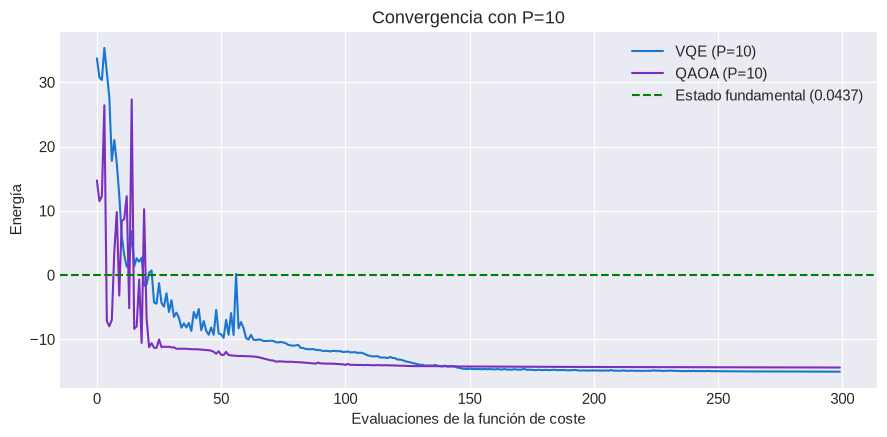

In [6]:
filas_alta, hist_alta = [], {}
for kind in ("VQE", "QAOA"):
    fila, h = ejecutar(kind, 10.0, 300, SEED); filas_alta.append(fila); hist_alta[kind] = h
tabla_alta = pd.DataFrame(filas_alta)
print(tabla_alta.to_string(index=False))

fig, ax = plt.subplots(figsize=(9, 4.5))
for kind, color in (("VQE", "#1976D2"), ("QAOA", "#7B2FBE")):
    ax.plot(hist_alta[kind], label=f"{kind} (P=10)", color=color, lw=1.5)
ax.axhline(energia_gs, color="green", ls="--", label=f"Estado fundamental ({energia_gs:.4f})")
ax.set_xlabel("Evaluaciones de la función de coste"); ax.set_ylabel("Energía"); ax.legend(); ax.set_title("Convergencia con P=10")
plt.tight_layout(); plt.savefig(OUT_FIGURES / "04_portafolio_convergencia.png", dpi=150, bbox_inches="tight"); plt.show()

p=1: energía mínima alcanzada = 4.5015 (óptimo 0.0437)


p=2: energía mínima alcanzada = 3.5982 (óptimo 0.0437)


p=3: energía mínima alcanzada = 1.0474 (óptimo 0.0437)


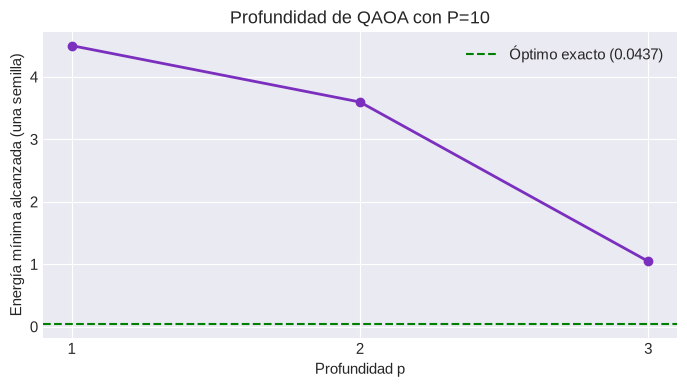

In [7]:
ham10, off10 = QuadraticProgramToQubo(penalty=10.0).convert(qp).to_ising()
profundidad = {}
for p in (1, 2, 3):
    ans = QAOAAnsatz(cost_operator=ham10, reps=p)
    rng = np.random.default_rng(SEED)
    res = minimize(lambda th, a=ans: float(estimator.run([(a, [ham10], [th])]).result()[0].data.evs[0]),
                   rng.random(ans.num_parameters), method="COBYLA", options={"maxiter": 150})
    profundidad[p] = res.fun + off10
    print(f"p={p}: energía mínima alcanzada = {profundidad[p]:.4f} (óptimo {exact_cost:.4f})")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(list(profundidad), list(profundidad.values()), marker="o", lw=2, color="#7B2FBE")
ax.axhline(exact_cost, color="green", ls="--", label=f"Óptimo exacto ({exact_cost:.4f})")
ax.set_xticks([1, 2, 3]); ax.set_xlabel("Profundidad p"); ax.set_ylabel("Energía mínima alcanzada (una semilla)")
ax.set_title("Profundidad de QAOA con P=10"); ax.legend(); plt.tight_layout()
plt.savefig(OUT_FIGURES / "04_portafolio_qaoa_depth.png", dpi=150, bbox_inches="tight"); plt.show()

## 7. Estadística sobre semillas (`python -m qml_v2.portfolio`)

Cada fila resume 10 semillas independientes; en la configuración de penalización alta cada semilla usa 5 reinicios de COBYLA y
conserva la mejor cartera **factible** (evaluada en el problema original, no en la energía penalizada). La brecha es
$100\,(\text{coste}-\text{óptimo})/|\text{óptimo}|$; solo se promedian las semillas que devolvieron una cartera factible.

Óptimo exacto: ['EC', 'CIB', 'MSFT'] (coste 0.0437); Greedy: ['EC', 'CIB', 'MSFT'] (coste 0.0437)
    configuracion metodo  semillas  factibles  optimo_encontrado  brecha_media_pct  brecha_mediana_pct  brecha_max_pct  coste_medio  tiempo_medio_s
penalizacion_alta   QAOA        10         10                  6           111.517               0.000         724.380        0.092         683.799
penalizacion_alta    VQE        10         10                  3            83.485              63.685         253.023        0.080           8.239
penalizacion_baja   QAOA        10          0                  0               NaN                 NaN             NaN          NaN          60.742
penalizacion_baja    VQE        10          0                  0               NaN                 NaN             NaN          NaN           2.124


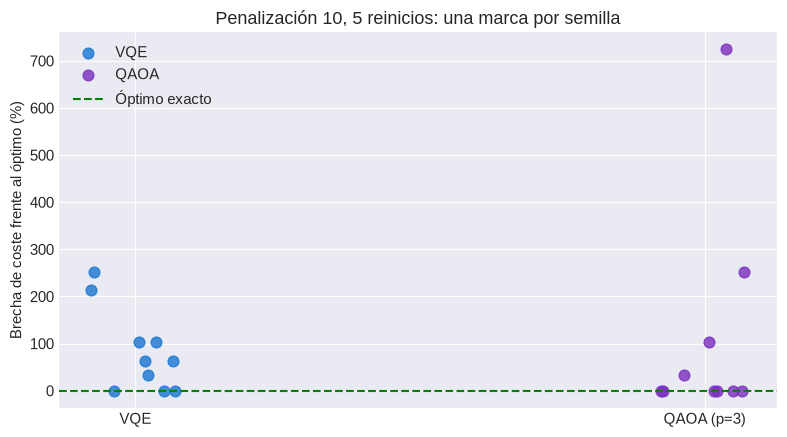

In [8]:
resumen = pd.read_csv(OUT_METRICS / "qml_v2_portfolio_summary.csv")
crudo = pd.read_csv(OUT_METRICS / "qml_v2_portfolio_raw.csv")
referencia = pd.read_json(OUT_METRICS / "qml_v2_portfolio_reference.json", typ="series")
print(f"Óptimo exacto: {referencia['activos_optimo']} (coste {referencia['optimo_exacto']:.4f}); "
      f"Greedy: {referencia['activos_voraz']} (coste {referencia['coste_voraz']:.4f})")
print(resumen.round(3).to_string(index=False))

alta = crudo[crudo["configuracion"] == "penalizacion_alta"]
fig, ax = plt.subplots(figsize=(8, 4.5))
for k, (metodo, color) in enumerate((("VQE", "#1976D2"), ("QAOA", "#7B2FBE"))):
    g = alta[alta["metodo"] == metodo]["brecha_pct"].dropna()
    ax.scatter(np.full(len(g), k) + np.random.default_rng(0).uniform(-0.08, 0.08, len(g)), g, color=color, s=60, alpha=0.8, label=metodo)
ax.axhline(0, color="green", ls="--", label="Óptimo exacto")
ax.set_xticks([0, 1]); ax.set_xticklabels(["VQE", "QAOA (p=3)"]); ax.set_ylabel("Brecha de coste frente al óptimo (%)")
ax.set_title("Penalización 10, 5 reinicios: una marca por semilla"); ax.legend(); plt.tight_layout()
plt.savefig(OUT_FIGURES / "04_portafolio_ventaja_cuantica.png", dpi=150, bbox_inches="tight"); plt.show()

## 8. Frontera riesgo–retorno

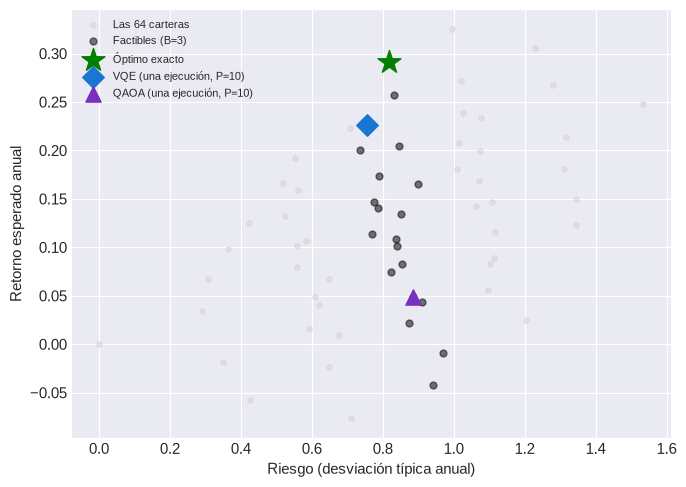

In [9]:
todas64 = []
for i in range(2 ** NUM_ASSETS):
    x = np.array([int(b) for b in format(i, f"0{NUM_ASSETS}b")][::-1])
    todas64.append({"retorno": mu @ x, "riesgo": np.sqrt(x @ sigma @ x), "factible": x.sum() == BUDGET})
df_all = pd.DataFrame(todas64); df_f = df_all[df_all["factible"]]
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(df_all["riesgo"], df_all["retorno"], c="lightgray", s=15, alpha=0.5, label="Las 64 carteras")
ax.scatter(df_f["riesgo"], df_f["retorno"], c="black", s=25, alpha=0.5, label=f"Factibles (B={BUDGET})")
ax.scatter(np.sqrt(exact_x @ sigma @ exact_x), mu @ exact_x, c="green", marker="*", s=300, label="Óptimo exacto")
for fila, marker, color in zip(filas_alta, ("D", "^"), ("#1976D2", "#7B2FBE")):
    if fila["factible"]:
        x = pf._bits(fila["cadena"])
        ax.scatter(np.sqrt(x @ sigma @ x), mu @ x, c=color, marker=marker, s=120, label=f"{fila['solver']} (una ejecución, P=10)")
ax.set_xlabel("Riesgo (desviación típica anual)"); ax.set_ylabel("Retorno esperado anual"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT_FIGURES / "04_portafolio_frontera.png", dpi=150, bbox_inches="tight"); plt.show()

## 9. Resultados de una ejecución (semilla 0)

In [10]:
filas = [{"modelo": "Exacto (enumeración)", "tipo": "clásico", "penalizacion": np.nan, "factible": True,
          "coste_qp": exact_cost, "activos": ", ".join(exact_assets), "tiempo_s": round(t_exact, 4)}]
for f in filas_baja + filas_alta:
    filas.append({"modelo": f"{f['solver']} (P={f['penalizacion']:g})", "tipo": "cuántico", "penalizacion": f["penalizacion"],
                  "factible": f["factible"], "coste_qp": f["coste_qp"], "activos": f["activos"], "tiempo_s": f["tiempo_s"]})
final = pd.DataFrame(filas)
final["brecha_pct"] = 100 * (final["coste_qp"] - exact_cost) / abs(exact_cost)
final.to_csv(OUT_METRICS / "04_portafolio_resultados.csv", index=False)
print(final.round(4).to_string(index=False))

              modelo     tipo  penalizacion  factible  coste_qp         activos  tiempo_s  brecha_pct
Exacto (enumeración)  clásico           NaN      True    0.0437   EC, CIB, MSFT    0.0051      0.0000
        VQE (P=0.01) cuántico          0.01     False       NaN        EC, MSFT    0.8000         NaN
       QAOA (P=0.01) cuántico          0.01     False       NaN                   10.6000         NaN
          VQE (P=10) cuántico         10.00      True    0.0586  EC, AAPL, MSFT    1.2000     34.0462
         QAOA (P=10) cuántico         10.00      True    0.3434 EC, GOOGL, AMZN   43.4000    685.4338


## 10. Lectura

* **Formulación válida.** Con $P=10$ el estado fundamental del Ising es exactamente la cartera óptima (Sección 4), de modo que cualquier
  brecha viene del optimizador variacional (COBYLA con inicio aleatorio sobre un paisaje no convexo), no del modelo.
* **La penalización importa.** Con $P=0.01$ los solvers convergen a estados que violan $\sum x_i=B$ (Sección 5).
* **Resultado sobre varias semillas.** Véase la tabla de la Sección 7: la calidad depende de la semilla; una sola ejecución no basta
  para afirmar ni ventaja ni desventaja. A $n=6$ la enumeración exacta son 20 evaluaciones y tarda microsegundos, de modo que no hay
  motivo práctico para un solver cuántico; la escala donde el problema sería duro ($n\gtrsim 30$) está fuera del simulador de vector de estados.
* **Limitaciones.** Simulación exacta sin ruido; seis activos; un único periodo; COBYLA con presupuesto fijo de evaluaciones.